# Clasificación de imágenes con una Red Neuronal Convolucional (CNN)

**Dataset:** CIFAR-10 · **Framework:** TensorFlow / Keras · **Entorno:** Google Colab

El objetivo es entrenar una CNN que mire una foto pequeña y diga qué hay en ella, eligiendo entre 10 clases. Al final el modelo queda guardado y lo usa una aplicación en Streamlit.

Antes de correr: en Colab ve a **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**. Con CPU el entrenamiento tarda horas. Con GPU, unos minutos.

## 1. Librerías

In [2]:
import json
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Selección y descripción del dataset

Usé **CIFAR-10**, publicado en 2009 por Alex Krizhevsky, Vinod Nair y Geoffrey Hinton en la Universidad de Toronto. Viene incluido en Keras, así que se descarga con una línea y no hay que subir nada a Drive.

Este cuenta con 60.000 imágenes, suficientes para entrenar una CNN desde cero sin que se aprenda las fotos de memoria. Las 10 clases están perfectamente balanceadas, 6.000 imágenes cada una, así que el accuracy se puede leer sin trampas. Y las imágenes son de 32x32 píxeles, lo que permite entrenar en Colab gratis en pocos minutos.

| Característica | Valor |
|---|---|
| Imágenes totales | 60.000 (50.000 entrenamiento + 10.000 prueba) |
| Tamaño | 32 x 32 píxeles, a color (3 canales RGB) |
| Clases | 10, con 6.000 imágenes cada una |
| Tipo de problema | Clasificación multiclase supervisada |

Las clases son: avión, automóvil, pájaro, gato, ciervo, perro, rana, caballo, barco y camión. Ninguna imagen tiene dos clases a la vez.

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

CLASES = ["avión", "automóvil", "pájaro", "gato", "ciervo",
          "perro", "rana", "caballo", "barco", "camión"]

print("Entrenamiento:", x_train_full.shape, y_train_full.shape)
print("Prueba:       ", x_test.shape, y_test.shape)
print("Tipo de dato de los píxeles:", x_train_full.dtype)
print("Rango de valores:", x_train_full.min(), "a", x_train_full.max())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 882s 5us/step
Entrenamiento: (50000, 32, 32, 3) (50000, 1)
Prueba:        (10000, 32, 32, 3) (10000, 1)
Tipo de dato de los píxeles: uint8
Rango de valores: 0 a 255


Las etiquetas vienen en forma `(50000, 1)`, una columna con un número del 0 al 9. Las aplano a un vector simple porque así es más cómodo trabajar con ellas.

In [4]:
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()
print("Primeras 10 etiquetas:", y_train_full[:10])
print("Que corresponden a:", [CLASES[i] for i in y_train_full[:10]])

Primeras 10 etiquetas: [6 9 9 4 1 1 2 7 8 3]
Que corresponden a: ['rana', 'camión', 'camión', 'ciervo', 'automóvil', 'automóvil', 'pájaro', 'caballo', 'barco', 'gato']


## 3. Exploración y visualización de las imágenes

### 3.1 ¿Cuántas imágenes hay por clase?

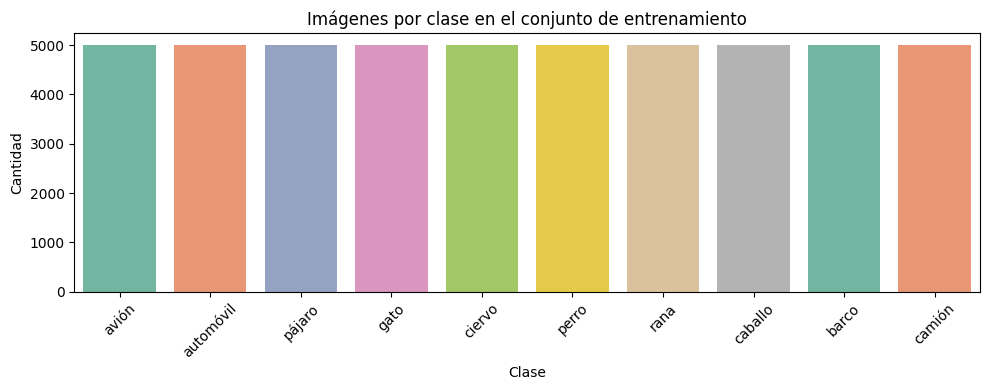

avión        5000
automóvil    5000
pájaro       5000
gato         5000
ciervo       5000
perro        5000
rana         5000
caballo      5000
barco        5000
camión       5000
Name: count, dtype: int64


In [6]:
conteo = pd.Series(y_train_full).value_counts().sort_index()
conteo.index = CLASES

plt.figure(figsize=(10, 4))
sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette="Set2", legend=False)
plt.title("Imágenes por clase en el conjunto de entrenamiento")
plt.ylabel("Cantidad")
plt.xlabel("Clase")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("reports/imagenes_por_clase.png", dpi=120)
plt.show()

print(conteo)

Todas las barras deberían medir lo mismo, 5.000 imágenes por clase en entrenamiento. Con un dataset balanceado no hace falta compensar ninguna clase.

### 3.2 Ejemplos de cada clase

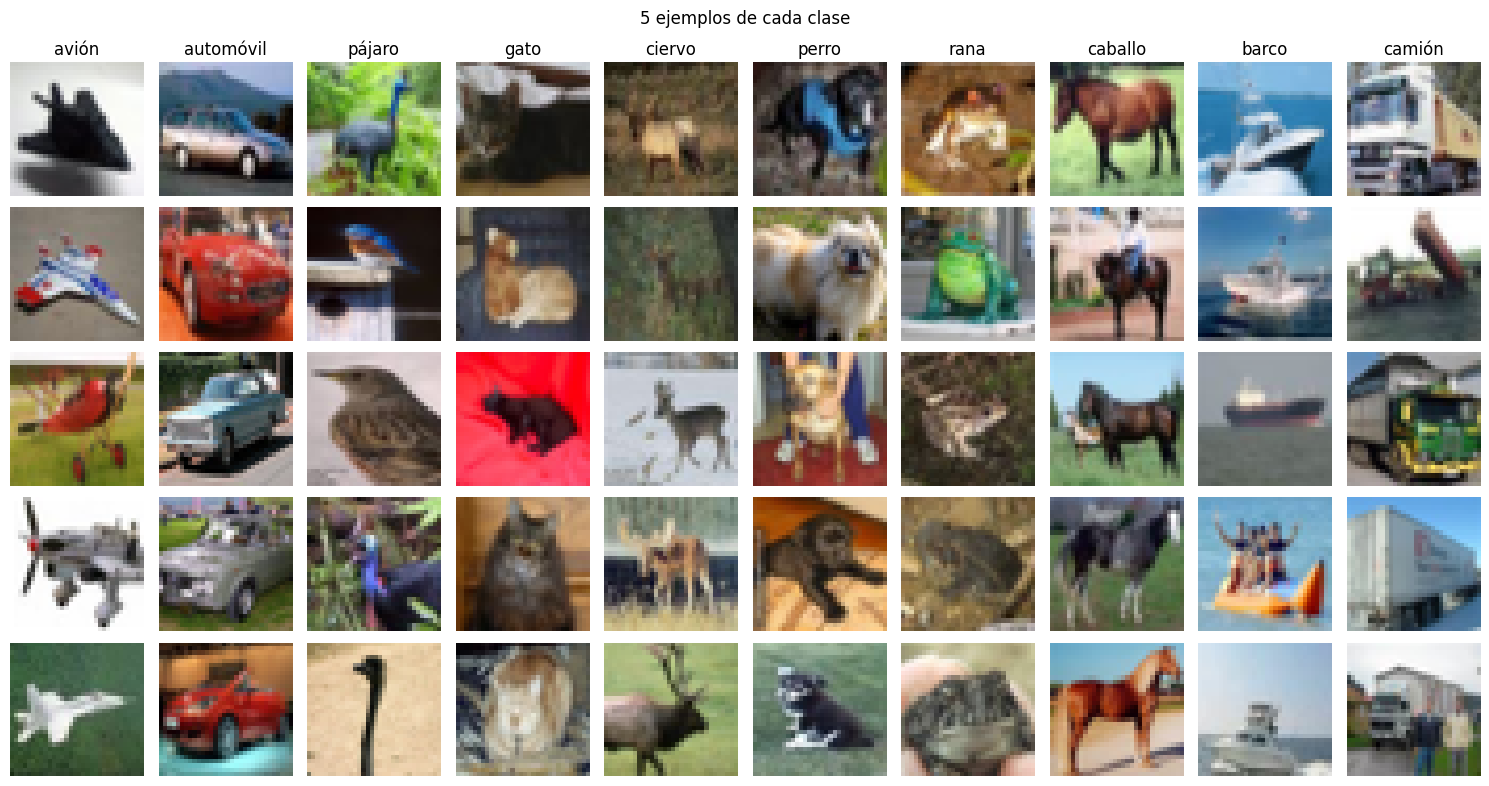

In [7]:
fig, ejes = plt.subplots(5, 10, figsize=(15, 8))
for col, clase in enumerate(CLASES):
    indices = np.where(y_train_full == col)[0][:5]
    for fila, idx in enumerate(indices):
        ejes[fila, col].imshow(x_train_full[idx])
        ejes[fila, col].axis("off")
    ejes[0, col].set_title(clase)
plt.suptitle("5 ejemplos de cada clase")
plt.tight_layout()
plt.savefig("reports/ejemplos_por_clase.png", dpi=120)
plt.show()

Se ve borroso, y es normal. 32x32 son apenas 1.024 píxeles. Gato y perro se parecen bastante a esta resolución, igual que automóvil y camión. Esas parejas probablemente sean las que más confunda el modelo.

### 3.3 Distribución de los colores

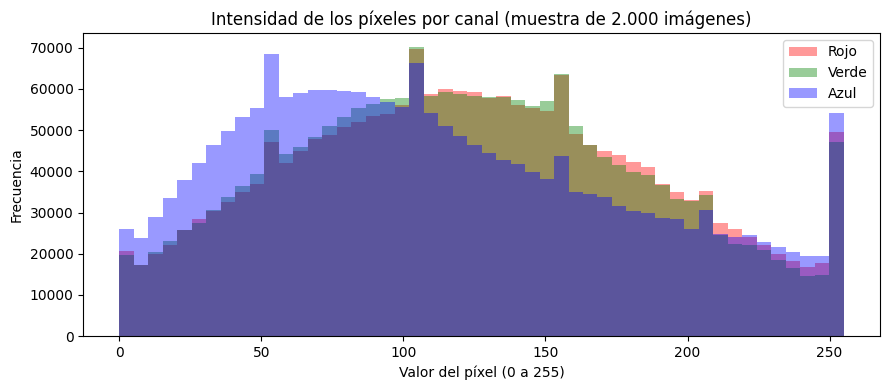

Promedio por canal (R, G, B): [125.3 123.  113.9]


In [9]:
muestra = x_train_full[:2000]
plt.figure(figsize=(9, 4))
for canal, color, nombre in zip(range(3), ["red", "green", "blue"], ["Rojo", "Verde", "Azul"]):
    plt.hist(muestra[:, :, :, canal].ravel(), bins=50, color=color, alpha=0.4, label=nombre)
plt.title("Intensidad de los píxeles por canal (muestra de 2.000 imágenes)")
plt.xlabel("Valor del píxel (0 a 255)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

print("Promedio por canal (R, G, B):", x_train_full.reshape(-1, 3).mean(axis=0).round(1))

Los píxeles van de 0 a 255. Ese rango es el que hay que normalizar en el siguiente paso.

## 4. Preprocesamiento y normalización

Las redes neuronales aprenden mejor con números pequeños. Divido cada píxel entre 255 para que todos queden entre 0 y 1. Es la misma operación que hace la aplicación Streamlit con las imágenes nuevas, y tiene que ser idéntica, porque si no el modelo recibiría algo distinto a lo que vio al entrenar.

In [10]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Nuevo rango:", x_train_full.min(), "a", x_train_full.max())
print("Tipo de dato:", x_train_full.dtype)

Nuevo rango: 0.0 a 1.0
Tipo de dato: float32


No hay valores faltantes que limpiar. Cada imagen es una matriz completa de 32x32x3, así que no aplica revisar nulos como en un dataset de tabla.

## 5. División en entrenamiento, validación y prueba

CIFAR-10 ya trae 10.000 imágenes de prueba separadas, y no se tocan hasta el final. Del entrenamiento saco un 10% para validación. Con `stratify` cada clase queda representada en la misma proporción en los dos lados.

- **Entrenamiento:** con estas aprende la red.
- **Validación:** se revisa en cada época para saber si está aprendiendo de verdad o memorizando.
- **Prueba:** el examen final, con imágenes que el modelo nunca vio.

In [11]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.10,
    stratify=y_train_full, random_state=SEMILLA)

print(f"Entrenamiento: {len(x_train):>6} imágenes")
print(f"Validación:    {len(x_val):>6} imágenes")
print(f"Prueba:        {len(x_test):>6} imágenes")

print("\nImágenes por clase en validación:")
print(pd.Series(y_val).value_counts().sort_index().set_axis(CLASES))

Entrenamiento:  45000 imágenes
Validación:      5000 imágenes
Prueba:         10000 imágenes

Imágenes por clase en validación:
avión        500
automóvil    500
pájaro       500
gato         500
ciervo       500
perro        500
rana         500
caballo      500
barco        500
camión       500
Name: count, dtype: int64


## 6. Data Augmentation

Sí hace falta. Cada clase tiene 4.500 imágenes de entrenamiento después de separar la validación, y una CNN con cientos de miles de parámetros puede aprenderse esas fotos de memoria. El Data Augmentation genera variaciones al vuelo en cada época: voltea la imagen, la gira un poco, le hace zoom o la desplaza. El modelo nunca ve exactamente la misma foto dos veces.

Una aclaración. Las capas de aumento solo actúan durante el entrenamiento. Al predecir o evaluar, Keras las desactiva sola, por eso pueden ir dentro del modelo sin afectar la aplicación.

No uso volteo vertical. Un barco al revés no aparece en fotos reales y solo confundiría a la red.

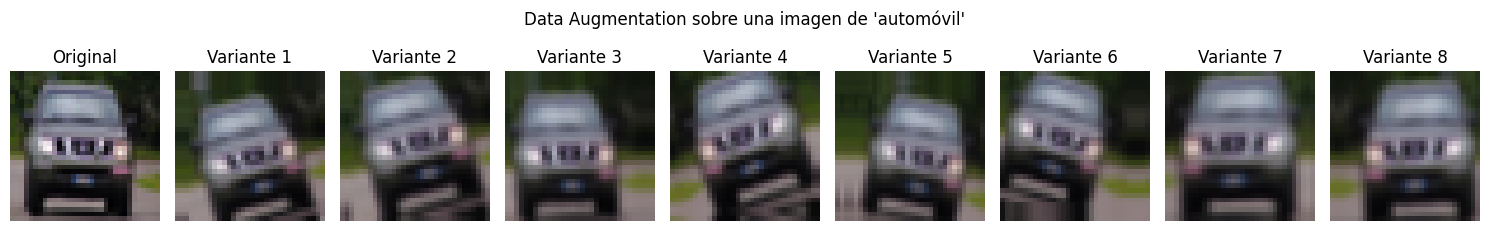

In [12]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

# Una misma imagen, transformada 8 veces
imagen = x_train[:1]
fig, ejes = plt.subplots(1, 9, figsize=(15, 2.5))
ejes[0].imshow(imagen[0])
ejes[0].set_title("Original")
ejes[0].axis("off")
for i in range(1, 9):
    ejes[i].imshow(np.clip(aumento(imagen, training=True)[0].numpy(), 0, 1))
    ejes[i].set_title(f"Variante {i}")
    ejes[i].axis("off")
plt.suptitle(f"Data Augmentation sobre una imagen de '{CLASES[y_train[0]]}'")
plt.tight_layout()
plt.savefig("reports/data_augmentation.png", dpi=120)
plt.show()

## 7. Construcción de la CNN

La red tiene tres bloques convolucionales y una parte final que decide la clase.

- **Conv2D:** filtros que recorren la imagen buscando patrones. En el primer bloque detectan bordes y colores; en el tercero, formas más complejas como una rueda o una oreja. Cada bloque duplica la cantidad de filtros: 32, 64 y 128.
- **BatchNormalization:** mantiene estables los valores que pasan entre capas. Acelera el entrenamiento.
- **MaxPooling2D:** reduce la imagen a la mitad quedándose con el valor más fuerte de cada zona. 32x32 pasa a 16x16, luego 8x8, luego 4x4.
- **Dropout:** apaga al azar un porcentaje de neuronas en cada paso (20%, 30%, 40% y 50%), para que la red no dependa de unas pocas.
- **Dense final con softmax:** 10 salidas, una por clase, que suman 1. Esa es la probabilidad que muestra la aplicación.

In [13]:
modelo = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    aumento,

    # Bloque 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # Bloque 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    # Bloque 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.4),

    # Clasificador
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(len(CLASES), activation="softmax"),
], name="cnn_cifar10")

modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])

modelo.summary()

Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

Uso `sparse_categorical_crossentropy` porque las etiquetas son números del 0 al 9 y no vectores one-hot. El optimizador es Adam, el más común para empezar.

## 8. Entrenamiento
Hasta 40 épocas, pero dos callbacks controlan cuándo parar:

- **EarlyStopping:** si la pérdida en validación no mejora en 6 épocas seguidas, corta y recupera los pesos de la mejor época.
- **ReduceLROnPlateau:** si se estanca 3 épocas, baja la tasa de aprendizaje a la mitad para afinar.

Con GPU T4 cada época tarda alrededor de 15 a 25 segundos.

In [14]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

historial = modelo.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=40,
    batch_size=64,
    callbacks=callbacks,
)

print("Épocas entrenadas:", len(historial.history["loss"]))

Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 28ms/step - accuracy: 0.3711 - loss: 1.8447 - val_accuracy: 0.4884 - val_loss: 1.4300 - learning_rate: 0.0010
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.5028 - loss: 1.3798 - val_accuracy: 0.5314 - val_loss: 1.3513 - learning_rate: 0.0010
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - accuracy: 0.5730 - loss: 1.2107 - val_accuracy: 0.5610 - val_loss: 1.3266 - learning_rate: 0.0010
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6155 - loss: 1.0921 - val_accuracy: 0.6444 - val_loss: 1.0459 - learning_rate: 0.0010
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6436 - loss: 1.0194 - val_accuracy: 0.6792 - val_loss: 0.9253 - learning_rate: 0.0010
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6668 - loss: 0.9615 - val_accuracy: 0.6358 - val_loss: 1.0500 - learning_rate: 0.0010
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.6850 - l

## 9. Gráficas del entrenamiento

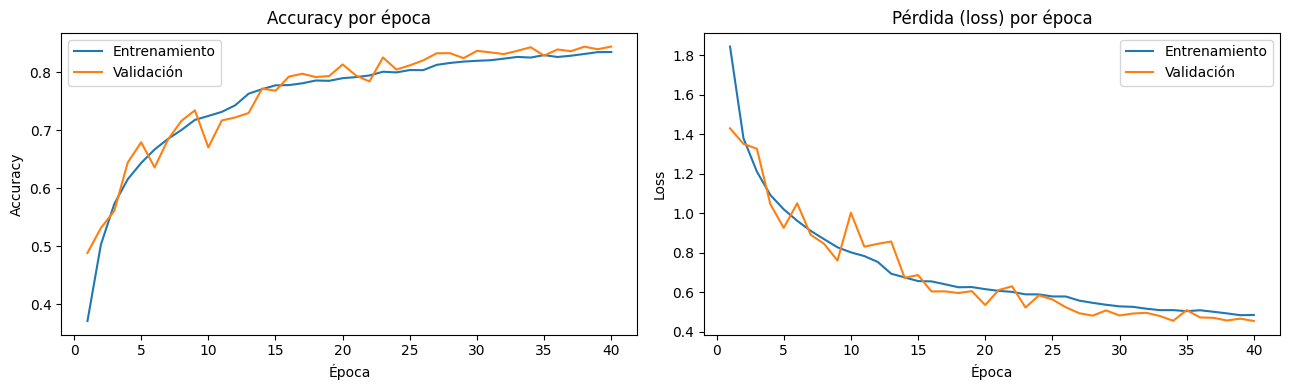

Mejor época: 40
  Accuracy entrenamiento: 0.8348
  Accuracy validación:    0.8442


In [16]:
h = historial.history
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

ejes[0].plot(range(1, len(h["accuracy"]) + 1), h["accuracy"], label="Entrenamiento")
ejes[0].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], label="Validación")
ejes[0].set_title("Accuracy por época")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Accuracy")
ejes[0].legend()

ejes[1].plot(range(1, len(h["loss"]) + 1), h["loss"], label="Entrenamiento")
ejes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="Validación")
ejes[1].set_title("Pérdida (loss) por época")
ejes[1].set_xlabel("Época")
ejes[1].set_ylabel("Loss")
ejes[1].legend()

plt.tight_layout()
plt.savefig("reports/entrenamiento.png", dpi=120)
plt.show()

mejor = int(np.argmin(h["val_loss"]))
print(f"Mejor época: {mejor + 1}")
print(f"  Accuracy entrenamiento: {h['accuracy'][mejor]:.4f}")
print(f"  Accuracy validación:    {h['val_accuracy'][mejor]:.4f}")

**Cómo leer las gráficas:** si las curvas de entrenamiento y validación van juntas, el modelo generaliza. Si la de entrenamiento sigue subiendo mientras la de validación se aplana o baja, empezó a memorizar (sobreajuste).

Las dos curvas avanzan juntas. El entrenamiento completó las 40 épocas sin que el EarlyStopping se activara, porque la pérdida de validación siguió bajando hasta el final: la mejor época fue la 40, con val_loss de 0.4533 y accuracy de validación de 0.8442.

La validación terminó por encima del entrenamiento, 0.8442 contra 0.8348. Parece raro, pero tiene explicación. Durante el entrenamiento el Dropout apaga neuronas y el Data Augmentation deforma las imágenes, así que la red aprende en condiciones más difíciles que las de validación, donde ninguna de las dos cosas está activa. No hay señal de sobreajuste.

ReduceLROnPlateau bajó la tasa de aprendizaje 4 veces, en las épocas 12, 26, 31 y 37, de 0.001 a 0.0000625. Hasta la época 12 la curva de validación da saltos grandes; después se estabiliza. El efecto más claro fue el de la época 26: en la siguiente, el accuracy de validación pasó de 0.8204 a 0.8326.

Como la pérdida seguía bajando en la última época, es posible que con 10 o 15 épocas más mejorara un poco. No lo probé.

## 10. Evaluación en el conjunto de prueba

Primero el accuracy y la pérdida generales. Después precision, recall y F1 por clase, porque el accuracy total puede esconder que el modelo falla mucho en una clase concreta.

- **Precision:** de las veces que dijo "gato", cuántas era gato de verdad.
- **Recall:** de todos los gatos reales, cuántos encontró.
- **F1:** el balance entre las dos.

In [17]:
perdida_test, accuracy_test = modelo.evaluate(x_test, y_test, verbose=0)
print(f"Accuracy en prueba: {accuracy_test:.4f}")
print(f"Pérdida en prueba:  {perdida_test:.4f}")

probabilidades = modelo.predict(x_test, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

reporte = classification_report(y_test, y_pred, target_names=CLASES, digits=3, zero_division=0)
print()
print(reporte)

with open("reports/metricas.txt", "w", encoding="utf-8") as f:
    f.write(f"Accuracy prueba: {accuracy_test:.4f}\nPérdida prueba: {perdida_test:.4f}\n\n{reporte}")

Accuracy en prueba: 0.8353
Pérdida en prueba:  0.4943

              precision    recall  f1-score   support

       avión      0.852     0.855     0.853      1000
   automóvil      0.901     0.963     0.931      1000
      pájaro      0.845     0.735     0.786      1000
        gato      0.781     0.637     0.702      1000
      ciervo      0.843     0.785     0.813      1000
       perro      0.837     0.687     0.755      1000
        rana      0.703     0.960     0.812      1000
     caballo      0.858     0.904     0.880      1000
       barco      0.920     0.888     0.904      1000
      camión      0.850     0.939     0.892      1000

    accuracy                          0.835     10000
   macro avg      0.839     0.835     0.833     10000
weighted avg      0.839     0.835     0.833     10000



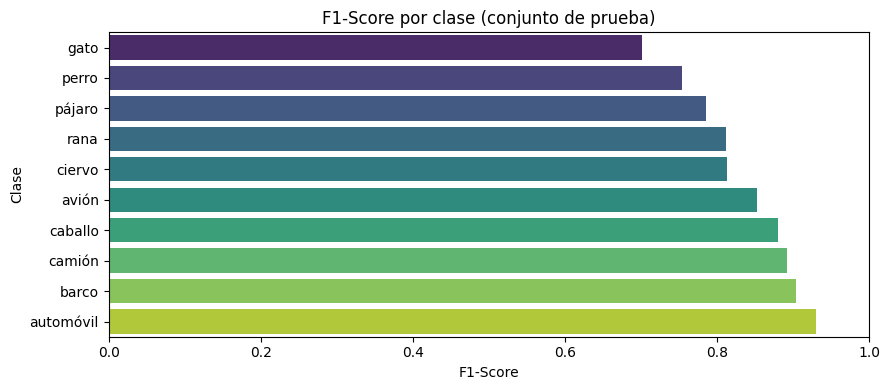

In [21]:
# F1 por clase en una gráfica, de menor a mayor
reporte_dict = classification_report(y_test, y_pred, target_names=CLASES, output_dict=True, zero_division=0)
f1_clases = pd.Series({c: reporte_dict[c]["f1-score"] for c in CLASES}).sort_values()

plt.figure(figsize=(9, 4))
sns.barplot(x=f1_clases.values, y=f1_clases.index, hue=f1_clases.index, palette="viridis", legend=False)
plt.title("F1-Score por clase (conjunto de prueba)")
plt.xlabel("F1-Score")
plt.ylabel("Clase")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig("reports/f1_por_clase.png", dpi=120)
plt.show()

En el conjunto de prueba, 10.000 imágenes que el modelo nunca vio, el accuracy fue 0.8353 y la pérdida 0.4943. Es casi un punto menos que en validación (0.8442), una diferencia normal.

La mejor clase fue automóvil, con F1 de 0.931: encontró el 96.3% de los autos reales. La peor fue gato, con 0.702. Ahí el problema es el recall: de 1.000 gatos, solo reconoció 637. Perro está cerca, con F1 de 0.755 y recall de 0.687. Gato y perro eran justo la pareja que más se parecía en la exploración.

Rana es un caso distinto. Su recall es altísimo, 0.960, pero su precision es la más baja de todas, 0.703. El modelo dice "rana" demasiado seguido: cerca de 400 imágenes de otras clases terminaron clasificadas así. La matriz de confusión debería mostrar de dónde vienen.

## 11. Matriz de confusión

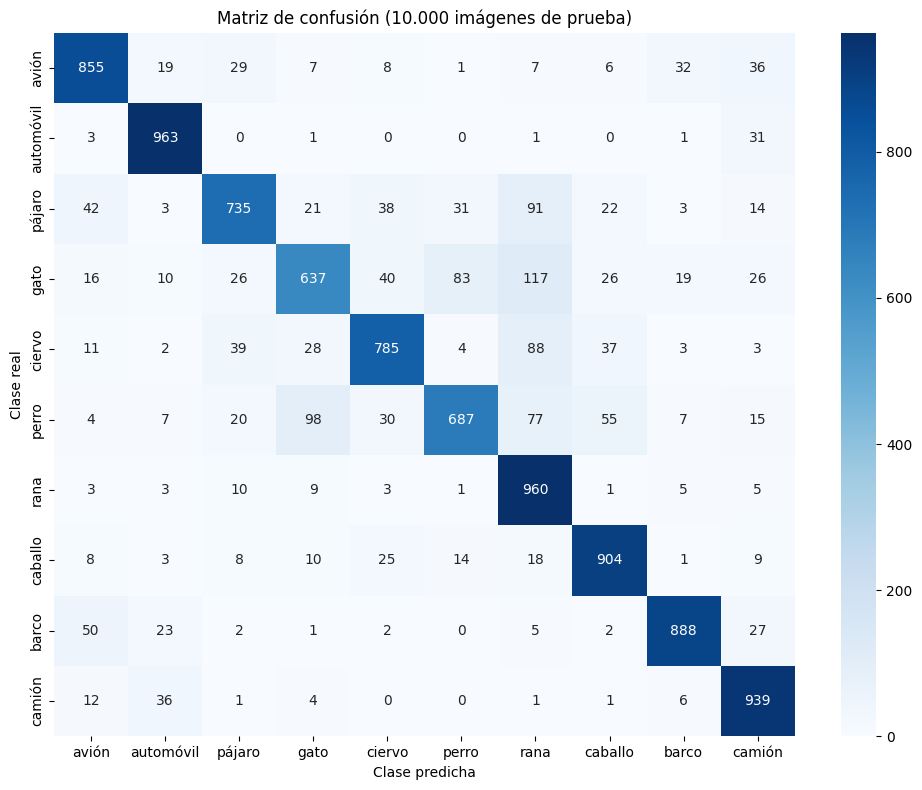

In [19]:
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión (10.000 imágenes de prueba)")
plt.tight_layout()
plt.savefig("reports/matriz_confusion.png", dpi=120)
plt.show()

La diagonal son los aciertos. Cada fila suma 1.000, porque hay 1.000 imágenes de cada clase en prueba. Para no buscar a ojo, esta celda lista las 5 confusiones más frecuentes:

In [22]:
confusiones = []
for real in range(len(CLASES)):
    for pred in range(len(CLASES)):
        if real != pred:
            confusiones.append((matriz[real, pred], CLASES[real], CLASES[pred]))

for cantidad, real, pred in sorted(confusiones, reverse=True)[:5]:
    print(f"{real:>10} confundido con {pred:<10}: {cantidad} veces")

      gato confundido con rana      : 117 veces
     perro confundido con gato      : 98 veces
    pájaro confundido con rana      : 91 veces
    ciervo confundido con rana      : 88 veces
      gato confundido con perro     : 83 veces


Las 5 confusiones más frecuentes son gato confundido con rana (117 veces), perro con gato (98), pájaro con rana (91), ciervo con rana (88) y gato con perro (83).

Lo de gato y perro se cumplió. Sumando las dos direcciones son 181 errores, el par más confundido de todo el conjunto. Automóvil y camión también se confunden, pero mucho menos: 67 en total, 31 autos tomados por camión y 36 camiones por auto.

Lo que no esperaba es rana. Tres de las cinco confusiones terminan ahí, y en total 405 imágenes de otras clases se clasificaron como rana. Casi todas son animales: 117 gatos, 91 pájaros, 88 ciervos y 77 perros. Mi sospecha es que la red asocia "rana" con un animal de tonos pardos o verdes sobre tierra o pasto, y esos fondos también aparecen en fotos de los otros animales. No lo comprobé.

Hay otro par que no estaba en la exploración: avión y barco, con 82 errores entre los dos. Ambos suelen tener fondo azul, cielo o mar.

## 12. Predicciones con imágenes

15 imágenes de prueba elegidas al azar. El título muestra la clase predicha, la real y la confianza. En verde los aciertos, en rojo los errores.

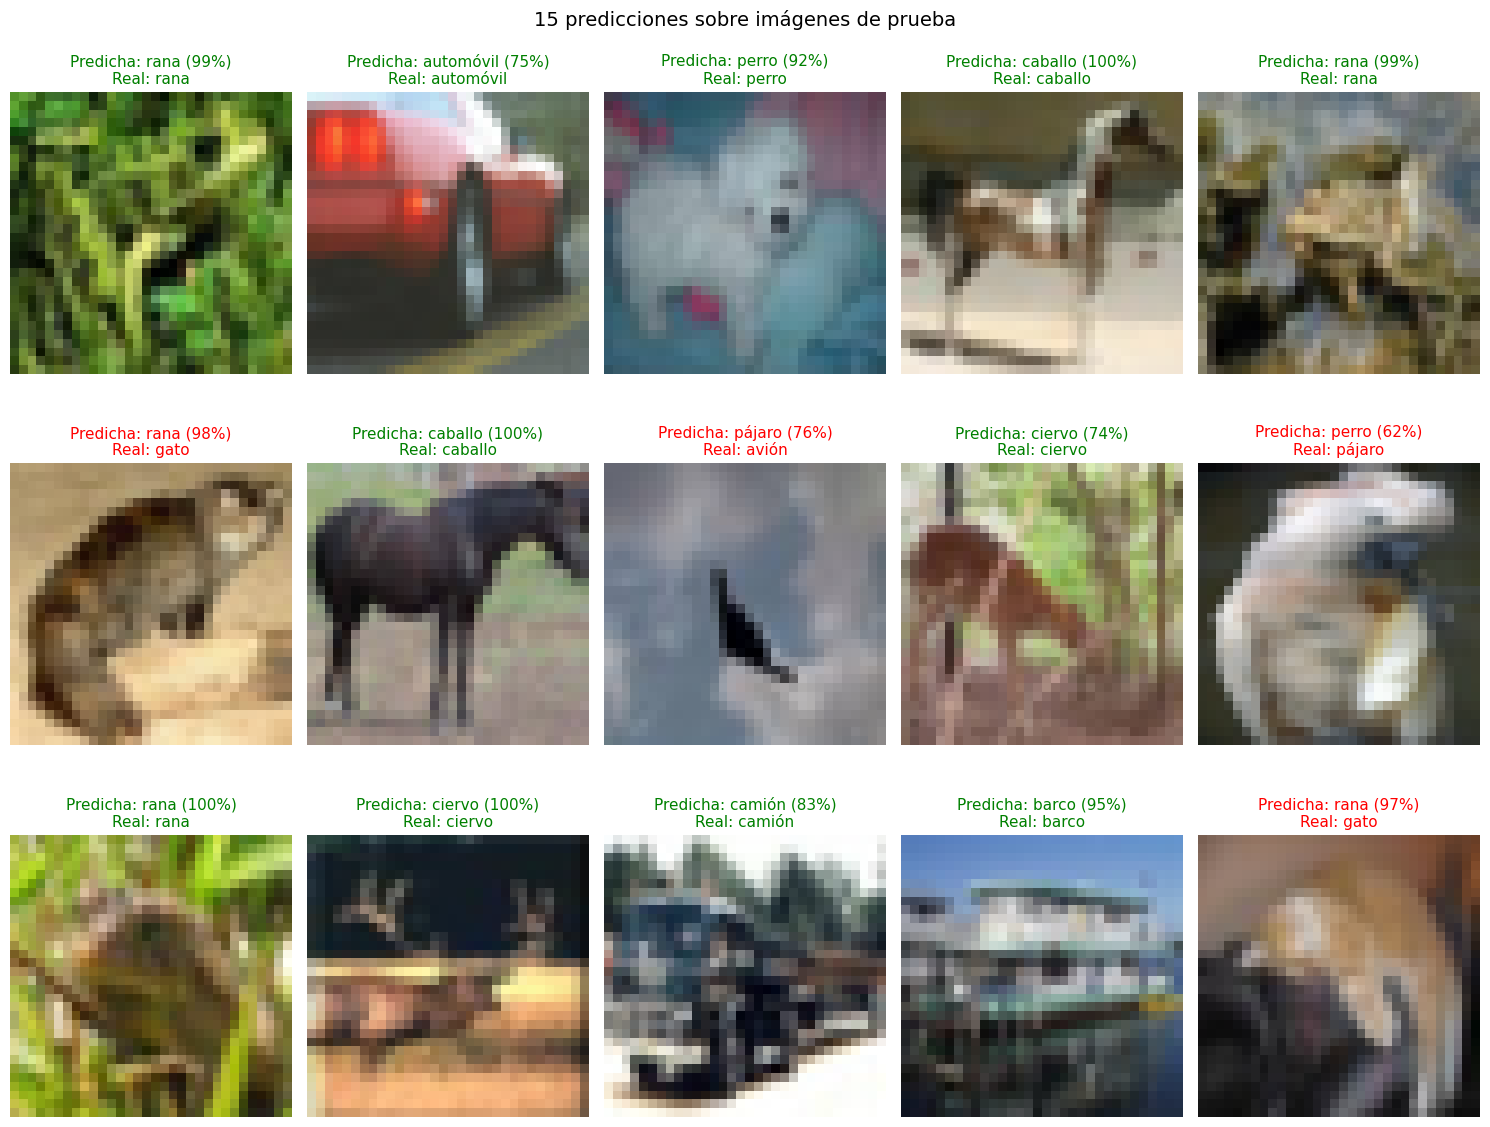

Aciertos en estas 15: 11


In [26]:
rng = np.random.default_rng(SEMILLA)
indices = rng.choice(len(x_test), size=15, replace=False)

fig, ejes = plt.subplots(3, 5, figsize=(15, 12))
for eje, idx in zip(ejes.ravel(), indices):
    pred = y_pred[idx]
    real = y_test[idx]
    confianza = probabilidades[idx][pred]
    eje.imshow(x_test[idx])
    eje.set_title(f"Predicha: {CLASES[pred]} ({confianza:.0%})\nReal: {CLASES[real]}",
                  color="green" if pred == real else "red", fontsize=11)
    eje.axis("off")
plt.suptitle("15 predicciones sobre imágenes de prueba", fontsize=14)
plt.tight_layout()
plt.savefig("reports/predicciones.png", dpi=120)
plt.show()

print("Aciertos en estas 15:", int((y_pred[indices] == y_test[indices]).sum()))

### Algunos errores del modelo

Mirar en qué se equivoca dice más que los aciertos. Estas son 10 imágenes mal clasificadas en las que el modelo estaba más seguro.

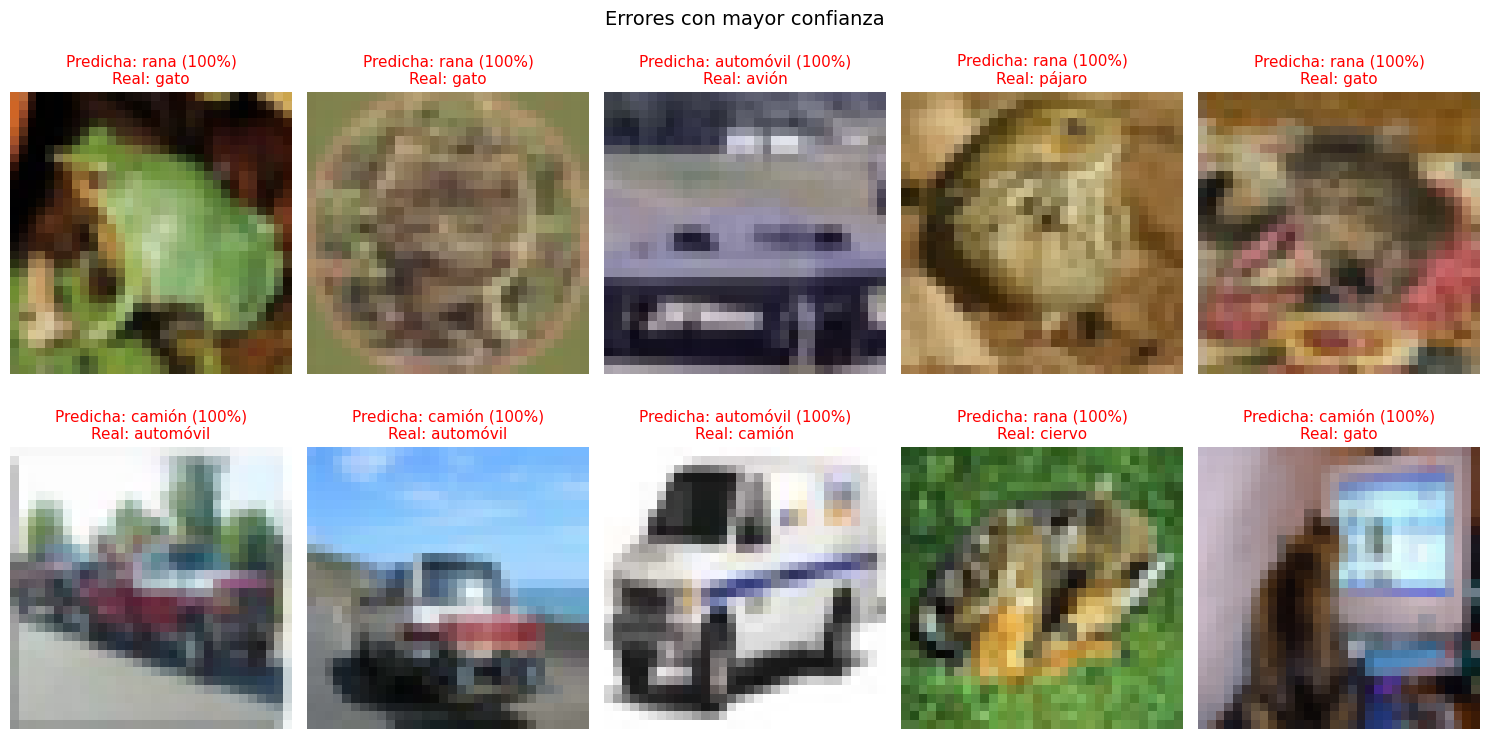

Total de errores: 1647 de 10000


In [28]:
errores = np.where(y_pred != y_test)[0]
confianza_errores = probabilidades[errores, y_pred[errores]]
peores = errores[np.argsort(confianza_errores)[::-1][:10]]

fig, ejes = plt.subplots(2, 5, figsize=(15, 8))
for eje, idx in zip(ejes.ravel(), peores):
    eje.imshow(x_test[idx])
    eje.set_title(f"Predicha: {CLASES[y_pred[idx]]} ({probabilidades[idx][y_pred[idx]]:.0%})\n"
                  f"Real: {CLASES[y_test[idx]]}", color="red", fontsize=11)
    eje.axis("off")
plt.suptitle("Errores con mayor confianza", fontsize=14)
plt.tight_layout()
plt.savefig("reports/errores.png", dpi=120)
plt.show()

print(f"Total de errores: {len(errores)} de {len(x_test)}")

## 13. Guardado del modelo entrenado

Guardo el modelo en formato `.keras`, el recomendado por Keras actualmente, y las clases en un JSON aparte para que la aplicación sepa qué nombre corresponde a cada salida.

In [29]:
modelo.save("models/cnn_cifar10.keras")
with open("models/clases.json", "w", encoding="utf-8") as f:
    json.dump(CLASES, f, ensure_ascii=False, indent=2)

print("Tamaño del modelo:", round(os.path.getsize("models/cnn_cifar10.keras") / 1e6, 2), "MB")

Tamaño del modelo: 6.75 MB


Compruebo que el archivo guardado funciona: lo cargo de nuevo y debe dar exactamente el mismo accuracy.

In [30]:
modelo_cargado = keras.models.load_model("models/cnn_cifar10.keras")
_, accuracy_cargado = modelo_cargado.evaluate(x_test, y_test, verbose=0)
print(f"Accuracy del modelo original: {accuracy_test:.4f}")
print(f"Accuracy del modelo cargado:  {accuracy_cargado:.4f}")

Accuracy del modelo original: 0.8353
Accuracy del modelo cargado:  0.8353


### Descargar los resultados de Colab

Colab borra los archivos al cerrar la sesión. Esta celda empaqueta `models/` y `reports/` en un zip y lo descarga. Su contenido va a las carpetas con el mismo nombre en el repositorio.

In [31]:
import zipfile

with zipfile.ZipFile("resultados_cnn.zip", "w") as zf:
    for carpeta in ["models", "reports"]:
        for archivo in os.listdir(carpeta):
            zf.write(os.path.join(carpeta, archivo))

try:
    from google.colab import files
    files.download("resultados_cnn.zip")
except ImportError:
    print("No estás en Colab: el zip quedó en la carpeta actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusiones

La CNN llegó a 83.53% de accuracy sobre las 10.000 imágenes de prueba. Para tener una referencia, adivinar al azar entre 10 clases daría 10%. El entrenamiento usó las 40 épocas disponibles, unos 10 minutos en una GPU T4, con una red de 552.874 parámetros.

No hubo sobreajuste. El accuracy de validación (0.8442) terminó por encima del de entrenamiento (0.8348), y la prueba quedó apenas un punto debajo de la validación. El Data Augmentation y el Dropout cumplieron su papel: la red nunca vio dos veces la misma foto exacta y no pudo apoyarse en unas pocas neuronas.

El rendimiento por clase es desigual. Los vehículos funcionan mejor: automóvil (F1 de 0.931), barco (0.904) y camión (0.892). Los animales cuestan más, sobre todo gato (0.702) y perro (0.755). Entre ellos dos suman 181 confusiones, el par más difícil del dataset.

Lo más llamativo fue la clase rana. Recibió 405 imágenes que no eran ranas, casi todas de animales: gatos, pájaros, ciervos y perros. Revisando los errores apareció otra cosa. Algunas imágenes etiquetadas como "gato" o "pájaro" son, a simple vista, ranas. Ahí el modelo acertó y el dataset se equivocó, así que una parte del 16.47% de error no es culpa de la red.

Qué probaría para mejorarlo:

- Más épocas. La pérdida de validación seguía bajando en la época 40, así que con 60 probablemente subiría algo.
- Un cuarto bloque convolucional de 256 filtros, para captar formas más complejas.
- Transfer learning con una red ya entrenada en millones de imágenes, como ResNet o EfficientNet. Es el camino más probable para pasar del 90%, aunque ya no sería una CNN construida desde cero.

Queda una duda abierta. No sé cuánto de la confusión con rana viene de los fondos (pasto, tierra) y cuánto de la forma del animal. Para saberlo habría que mirar qué zonas de la imagen activan la red, con una técnica como Grad-CAM, y eso quedó fuera de este trabajo.